<a href="https://colab.research.google.com/github/potopinc/colab/blob/main/ML_9_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Часть 1. Метод k ближайших соседей

## Импортируем библиотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.datasets import load_iris

## Загружаем данные

In [4]:
df = pd.read_csv('data-2.csv')
df.head()

,x,y,label
0,2.705480,1.989862,deepskyblue
1,-0.128224,1.075514,navy
2,2.454066,1.568876,deepskyblue
3,2.822180,2.226130,deepskyblue
4,0.152751,3.254361,navy


In [5]:
x = df[['x', 'y']].values
x
# признаки - свойства

array([[ 2.70547976,  1.98986223],
       [-0.12822381,  1.07551428],
       [ 2.45406593,  1.56887648],
       [ 2.82218036,  2.22612953],
       [ 0.15275149,  3.25436071],
       [ 1.50973504,  4.29179076],
       [ 0.67699201,  1.55108241],
       [ 0.74939617,  3.26359045],
       [ 1.84757801,  2.64184966],
       [ 2.87998065,  3.48034818],
       [ 1.21147201,  0.81513356],
       [ 3.69662907,  1.85707638],
       [ 2.04881362,  2.23983723],
       [ 2.44576001,  1.1080546 ],
       [ 1.83417889,  1.95424686],
       [ 3.02188774,  1.93573865],
       [ 2.48053527,  3.57261469],
       [ 1.77520319,  3.52434979],
       [ 0.16403095, -0.2859995 ],
       [ 2.86363132,  2.32761769],
       [ 2.3318945 ,  2.85584873],
       [ 0.89589038,  1.03542871],
       [ 2.39476893,  2.04660821],
       [ 1.5733128 ,  4.59273576],
       [ 2.3797766 ,  4.40688042],
       [ 1.54809573,  0.83559286],
       [ 1.33258609,  2.08205592],
       [ 1.62349375, -0.24576127],
       [ 1.18650413,

In [9]:
y = df['label']
y

,label
0,deepskyblue
1,navy
2,deepskyblue
3,deepskyblue
4,navy
5,deepskyblue
6,deepskyblue
7,deepskyblue
8,deepskyblue
9,deepskyblue


<function matplotlib.pyplot.grid(visible: 'bool | None' = None, which: "Literal['major', 'minor', 'both']" = 'major', axis: "Literal['both', 'x', 'y']" = 'both', **kwargs) -> 'None'>

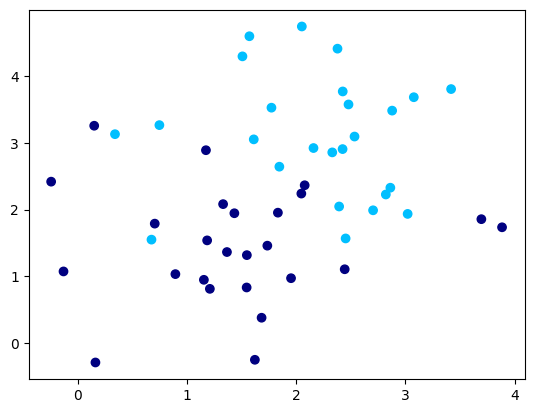

In [11]:
plt.scatter(x[:, 0], x[:, 1], c = y)
plt.grid

## Реализуем метод k ближайших соседей по приведенному шаблону.

Функция `calc_distance` должна возвращать евклидово расстояние между двумя точками в N-мерном пространстве

In [35]:
import numpy as np

def calc_distance(a, b):
    a = np.array(a)
    b = np.array(b)
    distance = np.sqrt(((a - b) ** 2).sum())
    return distance

Для класса `KnnClassificator` реализуйте следующие методы:

метод `__init__` определяет атрибуты;

метод `fit` запоминает обучающие данные;

метод `predict` должен возвращать самый популярный класс среди k ближайших соседей.

In [15]:
class KnnClassificator:

    def __init__(self, k):
       self.k = k # число соседей
       self.x = [] # матрица соседей
       self.y = [] # вектор ответа-меток (labels)

    # обучение модели (принимает матрицу объектов и вектор ответов)
    def fit(self, X, y):
        self.x = x
        self.y = y

    # предсказание значения для нового объекта
    def predict(self, x_new):
        result = []
        for index, x in enumerate(self.x):
          dis = calc_distance(x, x_new)
          result.append({'dist': dis, 'class': self.y[index]})

        result = sorted(result, key=lambda x: x['dist'])
        knn = result[:self.k]

        return Counter(obj['class'] for obj in knn).most_common()[0][0]


## Проверка

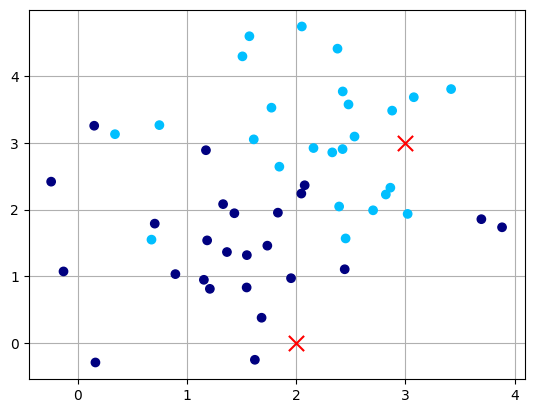

In [17]:
#Добавим данные, которые модель не видела

X_new = np.array([[2, 0], [3, 3]])

plt.scatter(x[:, 0], x[:, 1], c=y, zorder=5)
plt.scatter(X_new[:, 0], X_new[:, 1], c = 'red', zorder=5, marker = 'x', s = 120)
plt.grid();

In [19]:
knn = KnnClassificator(3)
knn.fit(x, y)
knn.predict(X_new[0])

#Вывод должен быть navy

'navy'

In [21]:
knn = KnnClassificator(3)
knn.fit(x, y)
knn.predict(X_new[1])

#Вывод должен быть deepskyblue

'deepskyblue'

## Работаем с реальными данными

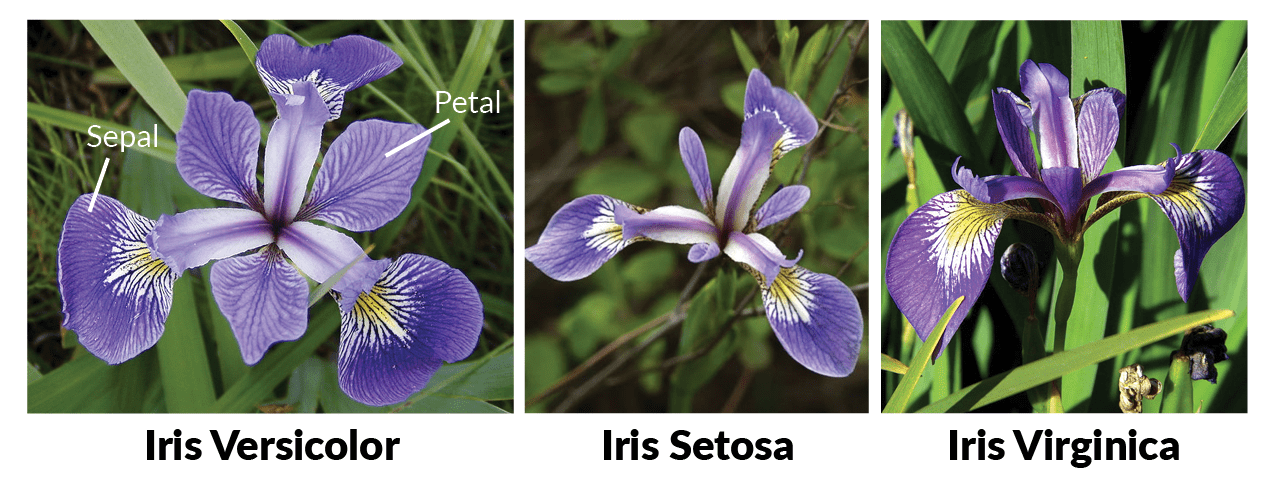


**Ирисы Фишера** (Fisher's Iris Dataset)

Данные о цветках ириса были собраны Эдгаром Андерсоном — ботаником, который в 1935 году опубликовал статью о морфологических различиях между видами ирисов.

В 1936 году Рональд Фишер использовал этот датасет в своей работе *The use of multiple measurements in taxonomic problems*. Он применил метод дискриминантного анализа для классификации видов ирисов.

- Число примеров (записей): 150.
- Число классов: 3 (0 — setosa, 1 — versicolor, 2 — virginica).
- Число признаков: 4 (длина чашелистика, ширина чашелистика, длина лепестка, ширина лепестка).
- Целевая переменная: вид ириса.

In [22]:
dataset = load_iris()
X = dataset['data']
y = dataset['target']

In [24]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [25]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

## Визуализируем данные

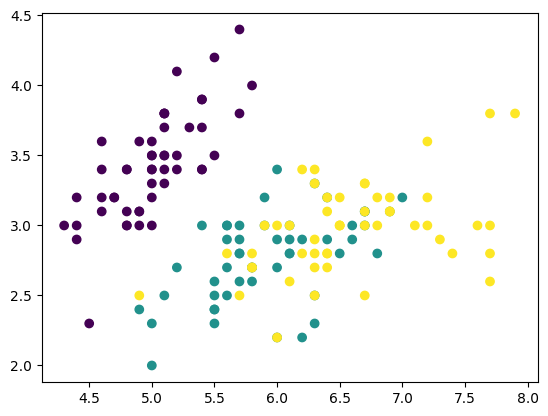

In [28]:
plt.scatter(X[:, 0], X[:, 1], c=y)

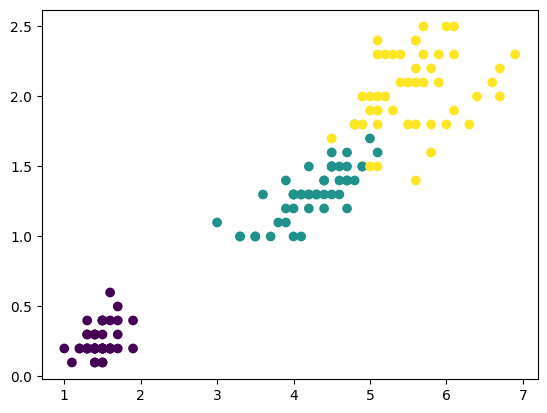

In [29]:
plt.scatter(X[:, 2], X[:, 3], c=y)

In [30]:
df = pd.DataFrame(X, columns=['col1', 'col2', 'col3', 'col4'])
df.head()

,col1,col2,col3,col4
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


array([[<Axes: xlabel='col1', ylabel='col1'>,
        <Axes: xlabel='col2', ylabel='col1'>,
        <Axes: xlabel='col3', ylabel='col1'>,
        <Axes: xlabel='col4', ylabel='col1'>],
       [<Axes: xlabel='col1', ylabel='col2'>,
        <Axes: xlabel='col2', ylabel='col2'>,
        <Axes: xlabel='col3', ylabel='col2'>,
        <Axes: xlabel='col4', ylabel='col2'>],
       [<Axes: xlabel='col1', ylabel='col3'>,
        <Axes: xlabel='col2', ylabel='col3'>,
        <Axes: xlabel='col3', ylabel='col3'>,
        <Axes: xlabel='col4', ylabel='col3'>],
       [<Axes: xlabel='col1', ylabel='col4'>,
        <Axes: xlabel='col2', ylabel='col4'>,
        <Axes: xlabel='col3', ylabel='col4'>,
        <Axes: xlabel='col4', ylabel='col4'>]], dtype=object)

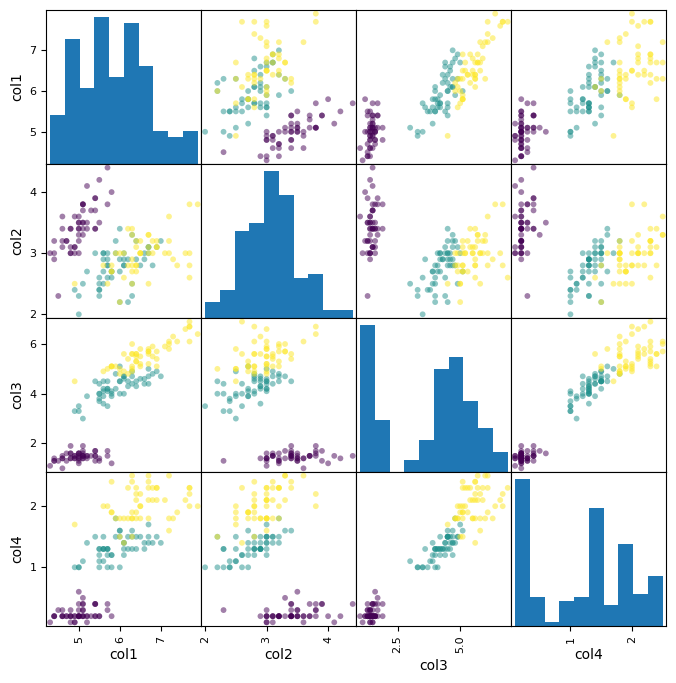

In [31]:
pd.plotting.scatter_matrix(df, c=y, s = 70, figsize=(8, 8))

## Обучаем модель и делаем предсказание

In [33]:
new_iris = [5, 1, 2, 3]

## Практика

**Задание 1**

Обучите классификатор с параметром k = 3 на заданной выборке.

Создайте функцию `acc_score(y, y_pred)`, которая будет вычислять метрику качества.

Рассчитайте `accuracy` для всей выборки.

**Задание 2**

Переберите k от 1 до 50.

При каком k качество будет наилучшим?

**Задание 3**

Постройте график изменения качества при различном k.

**Задание 4***

Мы реализовали класс `KnnClassificator`, но метод `predict` может делать только одно предсказание для точки `x_new`. Сделай так, чтобы метод `predict` мог делать предсказания сразу для нескольких новых точек.

In [ ]:
class KnnClassificator_(KnnClassificator):
  def predict_all(self, X_new):
    preds = []

    return preds

# Часть 2. Разделение данных, библиотека Sklearn

**ВАЖНО**

Перед началом работы запусти и выполни все ячейки части 1: среда выполнения -> запустить всё.

## Разделям данные

Визуализируем accuracy для обучающей и тестовой выборок при разном количестве соседей (от 1 до 50).

## Библиотека Sklearn

## Практика

**Задание 1**

Используя библиотеку Sklearn, постройте график метрики accuracy в зависимости от количества соседей (от 1 до 100).

**Задание 2**

Заново разбейте набор данных на Train и Test, но укажите методу `train_test_split` параметр `stratify=y`.

Постройте график, как в задании 1.

Сравните график с предыдущим.

**Задание 3**

Повторите задание 2, но на этот раз учитывайте расстояние от новой точки до ближайших соседей.

Для этого при создании `knn` укажите `weights='distance'`.

## Кросс-валидация

## Практика

**Задание 1**

Используя `cross_val_score` с параметром `cv = 5` построй график accuracy в зависимости от количества соседей (от 1 до 60).

Используй параметр `weights` для `KNeighborsClassifier` по умолчанию.

**Задание 2**

На график из задания 1 добавь еще 2 функции:
- значение cross_val_score при cv = 3;
- значение cross_val_score при cv = 10.

**Задание 3***

Самостоятельно изучи [LeaveOneOut](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.LeaveOneOut.html).

Сравни с `cross_val_score`.